In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np



In [5]:
df = pd.read_csv("house_price_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (15025, 18)


,House_ID,Area_sqft,Bedrooms,Bathrooms,Floors,Year_Built,Location,Furnishing_Status,Parking_Available,Garage_Count,Lot_Size_sqft,Condition,Distance_to_City_Center_km,Crime_Rate_Index,School_Rating,Has_Pool,Renovated,Price
0,3975,1665.3,2.0,4.0,1.0,1988,Green field,Unfurnished,NO,3.0,4817.2,Excellent,4.23,51.48,6.36,No,no,309277
1,12325,2646.2,2.0,5.0,2.0,2005,riverside,NaN,no,3.0,6998.6,EXCELLENT,3.67,14.55,7.45,yes,Y,563512
2,7202,2791.2,4.0,3.0,3.0,2011,Lake side,Unfurnished,NO,0.0,3427.6,good,8.97,38.84,NaN,Yes,no,495806
3,8355,1594.1,2.0,3.0,1.0,1972,Hillview,semifurnished,no,3.0,5703.1,fair,1.54,38.31,1.60,no,Yes,240776
4,12742,3227.0,3.0,5.0,2.0,1995,NaN,Unfurnished,yes,3.0,7352.4,Good,5.06,30.50,4.72,no,yes,413975


In [6]:
data = df[["Area_sqft", "Price"]].dropna()

X = data[["Area_sqft"]]   # Independent variable (must remain 2D)
y = data["Price"]         # Dependent variable

print("Rows available for modelling:", len(data))
print("Missing values after selection:")
print(data.isnull().sum())

Rows available for modelling: 14422
Missing values after selection:
Area_sqft    0
Price        0
dtype: int64


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 11537
Testing records: 2885


In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [9]:
b0 = model.intercept_
b1 = model.coef_[0]

print("Intercept (b0):", b0)
print("Slope (b1):", b1)
print(f"Regression equation: Predicted Price = {b0:.2f} + ({b1:.2f} × Area_sqft)")

Intercept (b0): 79530.40099478711
Slope (b1): 132.20855823389184
Regression equation: Predicted Price = 79530.40 + (132.21 × Area_sqft)


In [10]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Area_sqft": X_test["Area_sqft"].values,
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

display(comparison.head(10))

,Area_sqft,Actual_Price,Predicted_Price
0,1930.1,319616,334706.139242
1,2266.2,332891,379141.435664
2,2899.8,434849,462908.778161
3,2890.1,642273,461626.355147
4,3914.8,526479,597100.464769
5,2705.4,602706,437207.434441
6,2366.9,382713,392454.837479
7,3221.8,472724,505479.933913
8,3139.4,405976,494585.948714
9,3074.1,478964,485952.729862


In [11]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error (MAE): 57929.9
Mean Squared Error (MSE): 5322114033.14
Root Mean Squared Error (RMSE): 72952.82
R2 Score: 0.6698


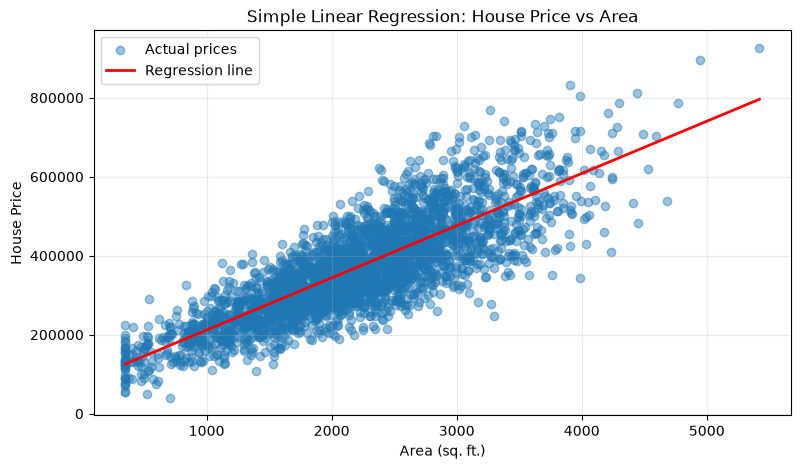

In [12]:
plt.figure(figsize=(9, 5))
plt.scatter(X_test["Area_sqft"], y_test, alpha=0.45, label="Actual prices")

# Sort x-values so the regression line is drawn smoothly
sorted_indices = np.argsort(X_test["Area_sqft"].values)
x_sorted = X_test["Area_sqft"].values[sorted_indices]
y_sorted = y_pred[sorted_indices]

plt.plot(x_sorted, y_sorted, color="red", linewidth=2, label="Regression line")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("House Price")
plt.title("Simple Linear Regression: House Price vs Area")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [13]:
new_area = pd.DataFrame({"Area_sqft": [2000]})
predicted_price = model.predict(new_area)[0]

print(f"Estimated price for a 2000 sq. ft. house: {predicted_price:,.2f}")

Estimated price for a 2000 sq. ft. house: 343,947.52
